In [ ]:
import numpy as np

distances = np.array([1.0, 2.0, 3.0])   # km : trajets A, B, C
durees    = np.array([4.0, 9.0, 12.0])  # minutes

def perte_quadratique_moyenne(w):
    erreurs = w * distances - durees
    return np.mean(erreurs ** 2)

def pente_de_la_perte(w):
    erreurs = w * distances - durees
    return 2 * np.mean(erreurs * distances)   # le 2 vient de la dérivée du carré

print(perte_quadratique_moyenne(0), pente_de_la_perte(0))
print(perte_quadratique_moyenne(58 / 14), pente_de_la_perte(58 / 14))

80.33333333333333 -38.666666666666664
0.23809523809523836 5.329070518200751e-15


ranger les distances et les durées des 3 trajets
perte(w) : erreurs = w × distances − durées ; moyenne des carrés
pente(w) : erreurs pareilles ; 2 × moyenne(erreurs × distances)
afficher perte et pente en w = 0
afficher perte et pente en w = 58/14, le fond du creux

In [2]:
def descente_de_gradient(pas, nombre_de_pas, w_depart=0.0):
    w = w_depart
    pertes = [float(perte_quadratique_moyenne(w))]
    for _ in range(nombre_de_pas):
        w = w - pas * pente_de_la_perte(w)
        pertes.append(float(perte_quadratique_moyenne(w)))
    return w, pertes

# Vérification : un seul pas de 0,05 doit redonner le calcul de la page
w_apres_un_pas, pertes = descente_de_gradient(pas=0.05, nombre_de_pas=1)
print(round(w_apres_un_pas, 2), [round(p, 1) for p in pertes])

# 20 pas pour chacun des trois taux
for pas in (0.01, 0.08, 0.23):
    w_final, pertes = descente_de_gradient(pas, nombre_de_pas=20)
    print(pas, round(w_final, 2), round(pertes[-1], 2))

1.93 [80.3, 23.0]
0.01 3.56 1.83
0.08 4.14 0.24
0.23 -59.84 19102.91


partir de w = 0 et noter la perte
répéter N fois : w ← w − pas × pente(w), noter la nouvelle perte
rendre le dernier w et la liste des pertes
vérifier : 1 pas de 0,05 → le chiffre de la page
puis 20 pas avec 0,01, 0,08 et 0,23 : afficher w final et perte finale

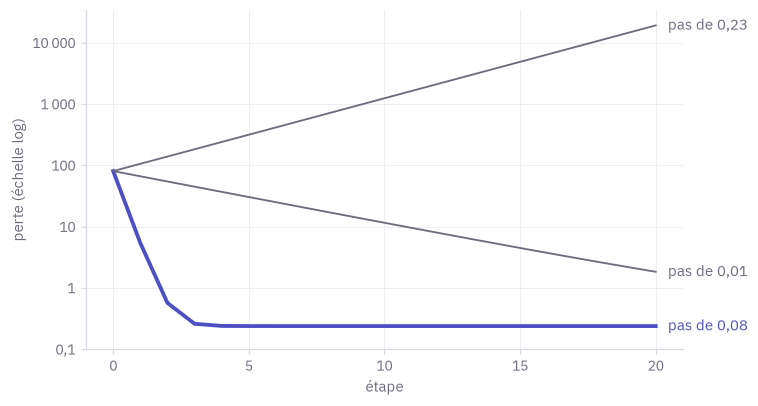

In [3]:
import sys
sys.path.insert(0, "../../../style")
from charte import charger_charte, sauver_clair_et_sombre
import matplotlib.pyplot as plt

charger_charte()

pertes_selon_le_pas = {pas: descente_de_gradient(pas, nombre_de_pas=20)[1] for pas in (0.01, 0.08, 0.23)}

def tracer(couleurs):
    figure, axe = plt.subplots(figsize=(7, 4))
    couleur_selon_le_pas = {0.01: couleurs["trait"], 0.08: couleurs["accent"], 0.23: couleurs["trait"]}
    for pas, pertes in pertes_selon_le_pas.items():
        couleur = couleur_selon_le_pas[pas]
        axe.plot(pertes, color=couleur, linewidth=2.5 if pas == 0.08 else 1.2)
        axe.annotate(f"pas de {pas}".replace(".", ","), (20, pertes[-1]), xytext=(8, 0),
                     textcoords="offset points", va="center", color=couleur)
    axe.set_yscale("log")  # 0,24 et 19 103 sur un même axe : seule l'échelle log montre les trois courbes
    axe.set_yticks([0.1, 1, 10, 100, 1000, 10000], ["0,1", "1", "10", "100", "1 000", "10 000"])
    axe.minorticks_off()
    axe.set_xticks(range(0, 21, 5))
    axe.set_xlabel("étape")
    axe.set_ylabel("perte (échelle log)")
    return figure

sauver_clair_et_sombre(tracer, "perte_selon_le_pas")

charger la charte (polices, couleurs)
pour chaque pas (0,01 ; 0,08 ; 0,23) : garder les 21 pertes de la descente
tracer une courbe par pas, chacune nommée au bout de sa ligne
axe vertical en échelle log, graduations écrites en français
enregistrer deux versions : _clair.png et _sombre.png